# Jacobian lens: read what each layer is disposed to make GPT-2 say

The logit lens decodes a block's residual stream directly through the model's final norm and
unembedding. Early and middle blocks often read out poorly that way. The Jacobian lens first
carries the residual vector into the final block's basis with one fixed linear map per block: the corpus-average Jacobian of the final
block's output with respect to block $l$'s output,

$$\mathrm{lens}_l(h) = \mathrm{unembed}\big(\mathrm{final\_norm}(J_l\,h)\big), \qquad
J_l = \mathbb{E}\left[\frac{\partial h_\mathrm{final}}{\partial h_l}\right].$$

The logit lens is the special case $J_l = I$.

Paper: Gurnee et al. (2026), "Verbalizable Representations Form a Global Workspace in Language
Models", Transformer Circuits, https://transformer-circuits.pub/2026/workspace/index.html.

TorchLens has no Jacobian-lens function; this notebook fits one from documented pieces: a trace
with `save_mode="view"`, which keeps every block's live output on the autograd graph,
`torch.autograd.grad`, and `trace.using("mechinterp").logit_lens(lens=...)`, which applies any per-block lens to a
trace (the public logit lens, `trace.using("mechinterp").logit_lens()`). The steps, on
GPT-2 small (124M parameters, CPU): (1) keep the live residual stream; (2) fit $J_l$ for every
block on a small corpus; (3) check the fit against `torch.func.jacrev` of the whole model, which
never touches TorchLens; (4) read both lenses on a held-out prompt; (5) measure, block by block,
how often each lens already names the model's own next token. The first cell downloads GPT-2
small from the Hugging Face Hub at a pinned revision; the fit takes a few minutes on a laptop CPU.

In [1]:
# recipe-test: tool=transformers_plot expected=True
import functools
import io
import time

import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, GPT2LMHeadModel

import torchlens as tl

REVISION = "607a30d783dfa663caf39e06633721c8d4cfcd7e"  # pragma: allowlist secret
model = GPT2LMHeadModel.from_pretrained(
    "openai-community/gpt2", revision=REVISION, attn_implementation="eager"
).eval()
model.config.use_cache = False
tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2", revision=REVISION)
blocks = [f"transformer.h.{index}" for index in range(model.config.n_layer)]
final_norm, unembed = model.transformer.ln_f, model.lm_head
d_model = model.config.n_embd
RESULT = len(blocks) == 12 and d_model == 768

.venv-ci-smoke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 3355.61it/s]


## 1. Keep the live residual stream

A trace in the default `save_mode="copy"` clones what it saves. The clone stays on the autograd
graph as a side branch, so the model's output cannot be differentiated with respect to it:
`torch.autograd.grad` finds no path and returns `None`. `save_mode="view"` stores the live
tensor itself, the one the next block consumed, so `trace[address].out` is a valid input for
`torch.autograd.grad` against anything downstream. One trace per prompt then yields every block's
residual stream on one graph.

In [2]:
# recipe-test: tool=transformers_plot expected=True
def residual_states(ids: torch.Tensor) -> list[torch.Tensor]:
    """Run one traced forward and return each block's live output, in block order."""
    trace = tl.trace(model, ids, capture=tl.options.CaptureOptions(save_mode="view"))
    return [trace[address].out for address in blocks]


ids = tokenizer("The quick brown fox jumps over the lazy dog", return_tensors="pt").input_ids
copied = tl.trace(model, ids)  # default save_mode="copy"
first, last = copied[blocks[0]].out, copied[blocks[-1]].out
through_copy = torch.autograd.grad(last.sum(), first, allow_unused=True)[0]
states = residual_states(ids)
through_view = torch.autograd.grad(states[-1].sum(), states[0])[0]
print(f"copy: gradient {through_copy}; view: gradient of shape {tuple(through_view.shape)}")
RESULT = through_copy is None and through_view.shape == states[0].shape

copy: gradient None; view: gradient of shape (1, 9, 768)


## 2. Fit $J_l$ on a corpus

The estimator follows the reference method. For one prompt, the final block's output is summed
over the valid target positions, and batched cotangents (one per output dimension, `chunk` at a
time) give one block of Jacobian rows per backward pass, for every earlier block at once. The
gradient at a source position therefore sums over all later targets; the rows are averaged over
source positions, then over prompts. The first positions are skipped (`skip_first`, where
attention-sink effects dominate) and the last position has no later target. Each prompt's
rows are cached by text, so a later fit that includes the same prompt reuses them. The corpus is
eight short sentences written for this notebook; it is a demonstration fit, and the paper
averages over far more text.

In [3]:
# recipe-test: tool=transformers_plot expected=True
CORPUS = [
    "The farmer walked across the wet field to check on the young lambs before breakfast.",
    "Our train was delayed by an hour, so we bought coffee and read the morning paper.",
    "She plays the violin in a small orchestra that performs every second Sunday.",
    "The bridge was closed for repairs, and drivers had to take the longer road.",
    "Scientists measured the temperature of the lake every week for ten years.",
    "He forgot his umbrella at the office and arrived home soaked to the skin.",
    "The library will extend its opening hours during the exam season next month.",
    "A strong wind knocked over the fence that separates the two gardens.",
]
skip_first, chunk = 4, 96


@functools.cache
def prompt_jacobians(text: str) -> dict[str, torch.Tensor]:
    """One prompt's Jacobian rows for every earlier block, averaged over its valid source positions."""
    ids = tokenizer(text, return_tensors="pt").input_ids
    states = residual_states(ids)
    valid = torch.arange(skip_first, ids.shape[1] - 1)
    target = states[-1][0, valid].sum(0)
    rows = {address: [] for address in blocks[:-1]}
    for cotangents in torch.eye(d_model).split(chunk):
        grads = torch.autograd.grad(
            target,
            states[:-1],
            grad_outputs=cotangents,
            is_grads_batched=True,
            retain_graph=True,
        )
        for address, grad in zip(blocks[:-1], grads, strict=True):
            rows[address].append(grad[:, 0, valid].sum(1) / len(valid))
    return {address: torch.cat(rows[address]) for address in blocks[:-1]}


def fit_jacobian_lens(texts: list[str]) -> dict[str, torch.Tensor]:
    """Corpus-average Jacobian of the last block's output w.r.t. each earlier block's."""
    per_prompt = [prompt_jacobians(text) for text in texts]
    return {
        address: sum(rows[address] for rows in per_prompt) / len(texts) for address in blocks[:-1]
    }


started = time.perf_counter()
lenses = fit_jacobian_lens(CORPUS)
print(
    f"fit {len(lenses)} matrices of shape {tuple(lenses[blocks[0]].shape)} in {time.perf_counter() - started:.0f} s"
)
RESULT = len(lenses) == 11 and lenses[blocks[0]].shape == (d_model, d_model)

fit 11 matrices of shape (768, 768) in 102 s


## 3. Check the fit against `torch.func.jacrev`

The check never touches TorchLens. It replaces block $l$'s output inside a plain forward of the
whole model with a forward hook, differentiates the final block's valid-position sum with
`torch.func.jacrev`, and reduces the result the same way as the fit. On one prompt (the corpus's
first, whose rows the fit already cached) the two estimates agree to float precision. `torch.func.jacrev` is a function transform, so it still
differentiates under an outer `torch.no_grad()`; the context only stops ordinary autograd from
also recording the parameters' gradient paths, which on GPT-2 small took more than 15 GB.

In [4]:
# recipe-test: tool=transformers_plot expected=True
def block_output(out: object) -> torch.Tensor:
    """Unwrap a GPT-2 block's output, a tensor or a tuple whose first item is the tensor."""
    return out[0] if isinstance(out, tuple) else out


def model_jacobian(index: int, ids: torch.Tensor) -> torch.Tensor:
    """Jacobian of the whole model with block ``index``'s output replaced by the jacrev input."""
    layers, seen = model.transformer.h, {}
    grab = layers[index].register_forward_hook(
        lambda m, i, out: seen.__setitem__("h", block_output(out))
    )
    model(ids)
    grab.remove()
    valid = torch.arange(skip_first, ids.shape[1] - 1)

    def suffix(h: torch.Tensor) -> torch.Tensor:
        patch = layers[index].register_forward_hook(
            lambda m, i, out: (h, *out[1:]) if isinstance(out, tuple) else h
        )
        last = layers[-1].register_forward_hook(
            lambda m, i, out: seen.__setitem__("last", block_output(out))
        )
        model(ids)
        patch.remove()
        last.remove()
        return seen["last"][0, valid].sum(0)

    # Outer no_grad: jacrev still differentiates h, but ordinary autograd no longer also
    # tracks the parameters, whose per-cotangent gradients would cost gigabytes on GPT-2.
    with torch.no_grad():
        jac = torch.func.jacrev(suffix, chunk_size=16)(seen["h"].detach())
    return jac[:, 0, valid].sum(1) / len(valid)


check_text = CORPUS[0]
one_prompt = fit_jacobian_lens([check_text])
check_ids = tokenizer(check_text, return_tensors="pt").input_ids
errors = {}
for index in (0, 6):
    reference = model_jacobian(index, check_ids)
    errors[blocks[index]] = float((one_prompt[blocks[index]] - reference).norm() / reference.norm())
    print(f"{blocks[index]}: relative error {errors[blocks[index]]:.1e}")
RESULT = max(errors.values()) < 1e-4

transformer.h.0: relative error 6.7e-07
transformer.h.6: relative error 2.5e-07


## 4. Read both lenses on a held-out prompt

`trace.using("mechinterp").logit_lens()` reconstructs the logit lens from the model's own head and checks it against
the captured logits. `trace.using("mechinterp").logit_lens(lens=...)` takes a mapping from block address to a
callable from residual state to logits; the Jacobian lens is one line per block, and the last
block's map is the identity by definition. Both results carry per-block logits and
`top_tokens()`. The prompt is not in the corpus.

In [5]:
# recipe-test: tool=transformers_plot expected=True
jacobian = {address: (lambda h, J=J: unembed(final_norm(h @ J.T))) for address, J in lenses.items()}
jacobian[blocks[-1]] = lambda h: unembed(final_norm(h))  # J = I at the final block

prompt = "The Eiffel Tower is in the city of"
with torch.no_grad():
    trace = tl.trace(model, tokenizer(prompt, return_tensors="pt").input_ids)
    plain = trace.using("mechinterp").logit_lens()
    jlens = trace.using("mechinterp").logit_lens(lens=jacobian, modules=blocks)


def tops(result: object) -> list[str]:
    """Top three tokens at the last position, one string per block."""
    return [
        " ".join(repr(tokenizer.decode(i)) for i in entry.top_k(3)[1].tolist())
        for entry in result.entries
    ]


print(f"prompt: {prompt!r}; lens sources: {plain.lens_source}, {jlens.lens_source}")
print(f"{'block':<16} {'Jacobian lens':<34} logit lens")
for address, j_row, p_row in zip(blocks, tops(jlens), tops(plain), strict=True):
    print(f"{address:<16} {j_row:<34} {p_row}")
RESULT = [entry.address for entry in jlens.entries] == blocks and plain.is_validated

prompt: 'The Eiffel Tower is in the city of'; lens sources: model_head, user
block            Jacobian lens                      logit lens
transformer.h.0  'ModLoader' ' tremend' 'senal'     ' the' ' course' ' a'
transformer.h.1  'ModLoader' ' tremend' 'senal'     ' the' ' course' ' a'
transformer.h.2  'ModLoader' ' tremend' ' mathemat' ' the' ' course' ' a'
transformer.h.3  'ModLoader' ' tremend' ' mathemat' ' the' ' course' ' a'
transformer.h.4  'ModLoader' ' Municip' ' mathemat' ' the' ' course' ' Z'
transformer.h.5  'ModLoader' ' Tulsa' ' Carnage'    ' the' ' England' ' course'
transformer.h.6  ' Buenos' ' Municip' ' Calais'     ' East' ' England' ' southwest'
transformer.h.7  ' Buenos' ' Constantinople' ' Kamp' ' Ing' ' Rome' ' La'
transformer.h.8  ' Constantinople' ' Naples' ' Mosul' ' Rome' ' London' ' Chicago'
transformer.h.9  ' Cologne' ' Amsterdam' ' Istanbul' ' London' ' Paris' ' Amsterdam'
transformer.h.10 ' Amsterdam' ' Cologne' ' Istanbul' ' Paris' ' London' ' Amsterdam'

## 5. How often each lens names the model's next token, block by block

For each block and each lens, the fraction of positions in held-out sentences where the lens's
top token equals the model's own top prediction there (`final_logits`, the captured output).
Positions inside `skip_first` are left out, as in the fit. The final block agrees by
construction for both lenses.

In [6]:
# recipe-test: tool=transformers_plot expected=True
HELD_OUT = [
    "The museum opens at nine in the morning and closes at five in the evening.",
    "When the river flooded, the whole village moved to the school on the hill.",
    "He wrote the first draft of his novel in a notebook he carried everywhere.",
    "The teacher asked the students to read the next chapter before Friday.",
    "Fresh bread from the bakery on the corner sells out before noon every day.",
    "The new bicycle lane runs from the station to the edge of the old town.",
]


def agreement(result: object) -> list[torch.Tensor]:
    """Per block: whether the lens's top token at each position matches the model's."""
    final = result.final_logits[0, skip_first:].argmax(-1)
    return [(entry.logits[0, skip_first:].argmax(-1) == final).float() for entry in result.entries]


scores = {"Jacobian lens": [], "logit lens": []}
with torch.no_grad():
    for text in HELD_OUT:
        trace = tl.trace(model, tokenizer(text, return_tensors="pt").input_ids)
        scores["Jacobian lens"].append(
            agreement(trace.using("mechinterp").logit_lens(lens=jacobian, modules=blocks))
        )
        scores["logit lens"].append(agreement(trace.using("mechinterp").logit_lens()))
curves = {
    name: [torch.cat([sentence[b] for sentence in runs]).mean().item() for b in range(len(blocks))]
    for name, runs in scores.items()
}
for name, values in curves.items():
    print(f"{name:<14}", " ".join(f"{v:.2f}" for v in values))
jacobian_curve, logit_curve = curves["Jacobian lens"], curves["logit lens"]
RESULT = jacobian_curve[-1] == logit_curve[-1] == 1.0 and jacobian_curve[10] > jacobian_curve[5]

Jacobian lens  0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.01 0.07 0.13 0.33 1.00
logit lens     0.16 0.10 0.12 0.10 0.13 0.16 0.16 0.19 0.18 0.33 0.58 1.00


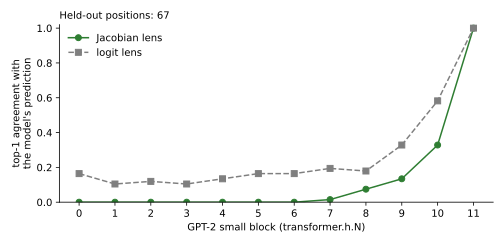

In [7]:
# recipe-test: tool=transformers_plot expected=True
fig, ax = plt.subplots(figsize=(7, 3.4))
styles = {"Jacobian lens": ("#2E7D32", "-", "o"), "logit lens": ("#7F7F7F", "--", "s")}
for name, values in curves.items():
    color, line, marker = styles[name]
    ax.plot(range(len(blocks)), values, color=color, linestyle=line, marker=marker, label=name)
ax.set_xticks(range(len(blocks)))
ax.set_xlabel("GPT-2 small block (transformer.h.N)")
ax.set_ylabel("top-1 agreement with\nthe model's prediction")
ax.set_ylim(0, 1.02)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
ax.set_title(
    f"Held-out positions: {sum(len(s[0]) for s in scores['logit lens'])}", fontsize=10, loc="left"
)
fig.tight_layout()
svg = io.BytesIO()
with plt.rc_context({"svg.hashsalt": "jacobian-lens"}):
    fig.savefig(svg, format="svg", metadata={"Date": None})
plt.close(fig)


class SVGFigure:
    """Show an SVG in Jupyter through its display protocol (_repr_svg_); plain Python ignores it."""

    def __init__(self, svg: bytes) -> None:
        self.svg = svg.decode("utf-8")

    def _repr_svg_(self) -> str:
        return self.svg

    def __repr__(self) -> str:
        return "<SVG figure>"


RESULT = len(ax.lines) == 2
SVGFigure(svg.getvalue())

## What the run shows

On the Eiffel Tower prompt the Jacobian lens's top token is a rare, unrelated one (`ModLoader`)
through block 5. From block 5 cities enter its top three (` Tulsa`, then ` Buenos`, ` Calais` and
` Constantinople`), while the logit lens still reads ` England` and ` East`. The logit lens reaches the
answer first: ` Paris` is its second token at block 9 and its first at block 10, where the
Jacobian lens reads ` Amsterdam`.

Over the held-out sentences, the Jacobian lens fitted on eight sentences agrees with the model's
own top token less often than the logit lens at every block before the last: near zero through
block 7, then 0.33 at block 10 against 0.58. Top-1 agreement asks for the exact next token, so it
does not score a readout that names the right kind of answer, which is what the table shows in
the middle blocks. The reference method averages its Jacobians over thousands of positions; this
notebook shows the mechanics on a small corpus and does not reproduce the paper's results.

## Limits and where to go next

- The lens is a corpus statistic, and eight sentences is a small corpus: the matrices are noisy
  and the early blocks' readouts are the least reliable. Pass more text to `fit_jacobian_lens`
  for a usable lens; cost grows linearly with the number of prompts.
- The fit costs `d_model / chunk` batched backward passes per prompt through the whole model
  suffix; `chunk` trades memory for speed.
- `residual_states` keeps one forward's autograd graph alive until that prompt's rows are done.
  Long sequences on large models need `chunk` lowered.
- `save_mode="view"` stores live aliases: a model that wrote its residual stream in place after a
  block would change the saved state. GPT-2 does not; for a model that might,
  `save_mode="reference"` keeps the same live tensor and raises `MutatedReferenceError` on a read
  after an in-place write.
- A trace captured under `torch.no_grad()` has no graph to differentiate: the fit runs with
  gradients on, and only the readouts are wrapped in `torch.no_grad()`.

The [Jacobian lens field guide page](../../docs/field-guide/jacobian_lens.md) runs the same
recipe on a tiny randomly initialized GPT-2 with no download, and
`examples/jacobian_lens_demo.py` is the command-line version of this notebook.